# Week 7 Practical — Feature Engineering 🔧⚡

**Goal:** turn raw energy time series into useful, defensible features — and explain *why* each feature exists.

This practical is intentionally different from a step-by-step tutorial. You will:

- ✏️ **complete small pieces of code** rather than write everything from scratch,
- 💬 **answer short interpretation questions**,
- 🧪 **change parameters and observe what happens**,
- 🎛️ use a few **interactive widgets**,
- 🤖 use an **LLM as a feature-idea generator**, then verify its suggestions yourself.

### Learning outcomes
By the end, you should be able to distinguish and apply:

1. **feature creation**,
2. **scaling**,
3. **transformation**,
4. **feature extraction** (conceptually),
5. **feature selection**,

and detect a particularly dangerous energy-forecasting problem: **data leakage**.

> **Working rule:** a feature is useful only if it is meaningful **and available at prediction time**.


In [ ]:
# Core imports
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_regression
from IPython.display import display, Markdown

# Interactive widgets
try:
    import ipywidgets as widgets
    from ipywidgets import interact
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print("ipywidgets is not installed. The core exercises still work, but interactive cells will be skipped.")


def TODO(message="Complete this line"):
    raise NotImplementedError("TODO: " + message)


def nrmse(y_true, y_pred):
    """NRMSE (%) = RMSE / (max(y_true) - min(y_true)) * 100.

    Normalisation uses the observed target range in the evaluation set.
    Lower values indicate better predictions.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    target_range = y_true.max() - y_true.min()
    if target_range <= 0:
        raise ValueError("NRMSE is undefined when the evaluation target has zero range.")
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return 100 * rmse / target_range


pd.set_option("display.max_columns", 30)


## 0. Warm-up — what kind of feature-engineering operation is this? 🧠

Before touching the data, classify a few operations. This mirrors the five-operation view from the lecture.


In [ ]:
# @title
# Small helper for self-check multiple-choice questions

def mcq(question, options, correct, explanation=""):
    if not WIDGETS_AVAILABLE:
        print(question)
        print("Options:", options)
        return

    choice = widgets.RadioButtons(options=options, description="")
    button = widgets.Button(description="Check")
    out = widgets.Output()

    def _check(_):
        with out:
            out.clear_output()
            if choice.value == correct:
                print("✅ Correct.", explanation)
            else:
                print("❌ Try again.")

    button.on_click(_check)
    display(Markdown(f"**{question}**"), choice, button, out)


In [ ]:
# @title
mcq(
    "Replacing temperature, humidity and wind speed with PC1 and PC2 is…",
    ["Creation", "Scaling", "Transformation", "Extraction", "Selection"],
    "Extraction",
    "PCA produces a smaller dense representation from existing features."
)

mcq(
    "Keeping only the five features with the highest mutual information is…",
    ["Creation", "Scaling", "Transformation", "Extraction", "Selection"],
    "Selection",
    "The original features stay intact; we keep only a subset."
)

**Replacing temperature, humidity and wind speed with PC1 and PC2 is…**

RadioButtons(options=('Creation', 'Scaling', 'Transformation', 'Extraction', 'Selection'), value='Creation')

Button(description='Check', style=ButtonStyle())

Output()

**Keeping only the five features with the highest mutual information is…**

RadioButtons(options=('Creation', 'Scaling', 'Transformation', 'Extraction', 'Selection'), value='Creation')

Button(description='Check', style=ButtonStyle())

Output()

### 💬 Short answer
Why can *more* features make a model worse?

**Your answer:**  
`...`


---
# 1. Load the energy data ⚡

Both CSV files are read **directly from GitHub** at runtime; nothing is saved locally. An internet connection is required.


In [ ]:
# Read directly from GitHub (no local files or downloads)
ENERGY_URL = (
    'https://raw.githubusercontent.com/drmatson/energy_informatics/main/data/'
    'electricity-production%20and%20consumption_2022.csv'
)
elering = pd.read_csv(ENERGY_URL, sep=';', decimal=',')

# The source uses day.month.year hour:minute in Estonian local time.
elering['timestamp'] = pd.to_datetime(
    elering['Kuupaev (Eesti aeg)'].str.strip(),
    format='%d.%m.%Y %H:%M',
    errors='raise'
)
elering = elering.set_index('timestamp').sort_index()
demand = elering[['Tarbimine']].rename(columns={'Tarbimine': 'demand'}).copy()

print('Demand:', demand.shape, '| first:', demand.index.min(), '| last:', demand.index.max())
display(demand.head())


Demand: (8760, 1) | first: 2022-01-01 00:00:00 | last: 2022-12-31 23:00:00


,demand
timestamp,
2022-01-01 00:00:00,899.4
2022-01-01 01:00:00,892.1
2022-01-01 02:00:00,874.3
2022-01-01 03:00:00,860.1
2022-01-01 04:00:00,842.7


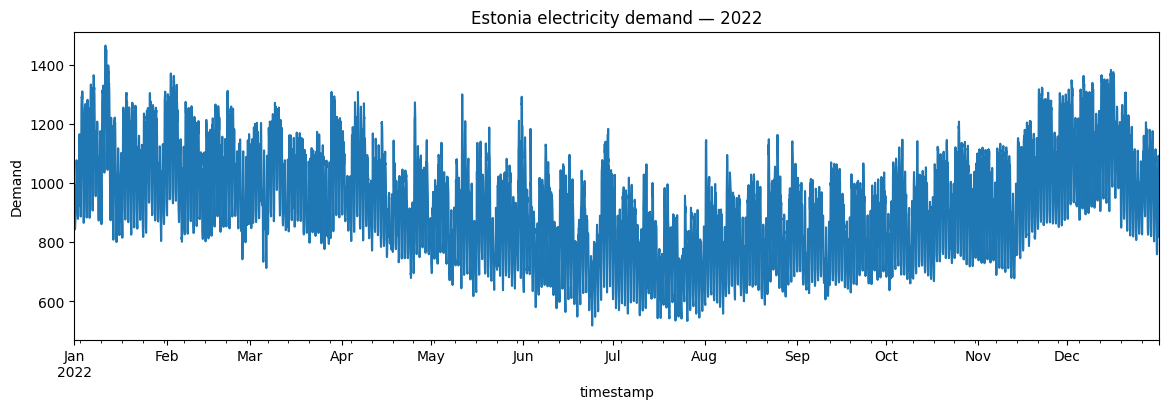

In [ ]:
# Quick visual check
ax = demand['demand'].plot(figsize=(14, 4), title='Estonia electricity demand — 2022')
ax.set_ylabel('Demand')
plt.show()

### 💬 Observe
Name **two repeating patterns** that you expect to exist in hourly electricity demand even before plotting individual weeks.

**Your answer:**  
1. `...`  
2. `...`


---
# 2. Feature creation — calendar features 📅

Complete only the missing pieces. Do not rewrite the whole cell.


In [ ]:
# ✏️ TODO 1 — complete the three calendar features

demand['hour'] = TODO("use the DatetimeIndex to extract hour")
demand['weekday'] = TODO("Monday=0, Sunday=6")
demand['is_weekend'] = TODO("1 for Saturday/Sunday, otherwise 0")

display(demand[['demand', 'hour', 'weekday', 'is_weekend']].head(30))

### 💬 Question
Why might using `hour = 0, 1, ..., 23` directly be awkward for some models?

Hint: think about the relationship between **23:00 and 00:00**.

**Your answer:**  
`...`


## 2.1 Cyclical encoding ⏰

Complete the periods in the sine/cosine formulas.


In [ ]:
# ✏️ TODO 2 — replace the TODO calls with the correct cycle lengths

HOURS_IN_CYCLE = TODO("how many hours are in a daily cycle?")
DAYS_IN_WEEK = TODO("how many weekday values are in the cycle?")

demand['hour_sin'] = np.sin(2 * np.pi * demand['hour'] / HOURS_IN_CYCLE)
demand['hour_cos'] = np.cos(2 * np.pi * demand['hour'] / HOURS_IN_CYCLE)
demand['weekday_sin'] = np.sin(2 * np.pi * demand['weekday'] / DAYS_IN_WEEK)
demand['weekday_cos'] = np.cos(2 * np.pi * demand['weekday'] / DAYS_IN_WEEK)

display(demand[['hour', 'hour_sin', 'hour_cos', 'weekday', 'weekday_sin', 'weekday_cos']].head())

### 🎛️ Interactive: raw distance vs cyclical distance
Move the two sliders. Try **23 and 0**, then **12 and 0**.


In [ ]:
def compare_hour_distance(h1=23, h2=0):
    raw_distance = abs(h1 - h2)

    p1 = np.array([
        np.sin(2*np.pi*h1/24),
        np.cos(2*np.pi*h1/24)
    ])
    p2 = np.array([
        np.sin(2*np.pi*h2/24),
        np.cos(2*np.pi*h2/24)
    ])
    cyclical_distance = np.linalg.norm(p1 - p2)

    print(f"Raw hour distance:      {raw_distance:.2f}")
    print(f"Cyclical 2D distance:   {cyclical_distance:.3f}")

if WIDGETS_AVAILABLE:
    interact(
        compare_hour_distance,
        h1=widgets.IntSlider(min=0, max=23, value=23, description='hour A'),
        h2=widgets.IntSlider(min=0, max=23, value=0, description='hour B')
    )
else:
    compare_hour_distance(23, 0)

interactive(children=(IntSlider(value=23, description='hour A', max=23), IntSlider(value=0, description='hour …

### 💬 Interpret
What did cyclical encoding fix?

**Your answer:**  
`...`


---
# 3. Leakage detective 🕵️‍♀️

Feature engineering is not just about inventing columns. A feature can look highly predictive because it accidentally contains the answer.

Assume the target is demand at time **t**.


In [ ]:
# @title
mcq(
    "Which rolling feature is SAFE for predicting demand at time t?",
    [
        "demand.rolling(24).mean()",
        "demand.shift(1).rolling(24).mean()",
        "demand.shift(-1).rolling(24).mean()"
    ],
    "demand.shift(1).rolling(24).mean()",
    "The window must end at t-1, not include the target at t or any future value."
)

**Which rolling feature is SAFE for predicting demand at time t?**

RadioButtons(options=('demand.rolling(24).mean()', 'demand.shift(1).rolling(24).mean()', 'demand.shift(-1).rol…

Button(description='Check', style=ButtonStyle())

Output()

## 3.1 Create safe lag and rolling features

The previous tutorial created lags and rolling statistics. Here, make the rolling feature explicitly **leakage-safe**.


In [ ]:
# ✏️ TODO 3 — complete the three lags

demand['lag1'] = TODO("previous hour")
demand['lag24'] = TODO("same hour yesterday")
demand['lag168'] = TODO("same hour one week ago")

# ✏️ TODO 4 — the rolling mean must use ONLY information available before time t
past_demand = TODO("shift demand so the current target is excluded")
demand['roll_mean_24h_safe'] = past_demand.rolling(24).mean()
demand['roll_std_24h_safe'] = past_demand.rolling(24).std()

display(demand[['demand', 'lag1', 'lag24', 'lag168', 'roll_mean_24h_safe']].head(175).tail(10))

### 💬 Leakage check
Why is this version unsafe?

```python
demand['roll_mean_24h'] = demand['demand'].rolling(24).mean()
```

**Your answer:**  
`...`


---
# 4. External + domain-specific features 🌦️🔥

Weather data also comes directly from GitHub. Dates are parsed explicitly as `DD.MM.YYYY HH:MM`; duplicate local timestamps at the autumn DST transition are averaged for the weather join.


In [ ]:
# Read weather directly from GitHub — do not save a local copy.
WEATHER_URL = (
    'https://raw.githubusercontent.com/drmatson/energy_informatics/main/data/'
    'weather_2022.csv'
)
weather = pd.read_csv(WEATHER_URL, sep=';', decimal='.', index_col=False, low_memory=False)

# Explicitly parse DD.MM.YYYY HH:MM; source rows are newest-first.
weather['timestamp'] = pd.to_datetime(
    weather['Local time in Tallinn (airport)'].astype(str).str.strip(),
    format='%d.%m.%Y %H:%M',
    errors='raise'
)

# Some columns mix measurements and text: coerce only the fields we need.
weather_cols = ['T'] + (['ff3'] if 'ff3' in weather.columns else [])
for col in weather_cols:
    weather[col] = pd.to_numeric(weather[col], errors='coerce')

weather_small = weather.set_index('timestamp')[weather_cols].sort_index()

# DST (autumn): local timestamps may repeat. Combine duplicate weather
# measurements so a join never multiplies the number of demand rows.
if weather_small.index.has_duplicates:
    print('Repeated local weather timestamps:', weather_small.index.duplicated().sum())
    weather_small = weather_small.groupby(level=0).mean()

weather_small = weather_small.rename(columns={
    'T': 'temperature', 'ff3': 'wind_speed'
})
demand = demand.join(weather_small, how='left', validate='many_to_one')

print('Weather dates:', weather_small.index.min(), 'to', weather_small.index.max())
print('Demand rows after join:', len(demand))
print('Missing temperature:', demand['temperature'].isna().sum())
display(demand[['demand', 'temperature']].head())


Repeated local weather timestamps: 1
Weather dates: 2022-01-01 00:00:00 to 2022-12-31 23:00:00
Demand rows after join: 8760
Missing temperature: 29


,demand,temperature
timestamp,,
2022-01-01 00:00:00,899.4,-1.0
2022-01-01 01:00:00,892.1,-0.6
2022-01-01 02:00:00,874.3,0.0
2022-01-01 03:00:00,860.1,-0.1
2022-01-01 04:00:00,842.7,-0.1


## 4.1 Heating degree feature

A simple domain feature is **heating degree** relative to a base temperature:

$$
HDD_t = \max(0, T_{base} - T_t)
$$

For this exercise, use **18°C** as the base.


In [ ]:
# ✏️ TODO 5 — complete the domain feature
BASE_TEMPERATURE = TODO("use 18 degrees C")
demand['heating_degree'] = TODO("use np.maximum(base - temperature, 0)")

display(demand[['temperature', 'heating_degree']].dropna().head(20))

In [ ]:
# Explore the relationship
sample = demand[['demand', 'temperature', 'heating_degree']].dropna().sample(
    min(2500, demand[['demand', 'temperature', 'heating_degree']].dropna().shape[0]),
    random_state=42
)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(sample['temperature'], sample['demand'], alpha=0.25, s=10)
ax[0].set_xlabel('Temperature [°C]')
ax[0].set_ylabel('Demand')
ax[0].set_title('Raw temperature')

ax[1].scatter(sample['heating_degree'], sample['demand'], alpha=0.25, s=10)
ax[1].set_xlabel('Heating degree')
ax[1].set_ylabel('Demand')
ax[1].set_title('Domain feature')
plt.tight_layout()
plt.show()

KeyError: "['heating_degree'] not in index"

### 💬 Think like a modeller
Is measured temperature at time **t** always available for a future forecast?

Choose one and explain:

- `YES, always`
- `NO — operational forecasting may need a weather forecast instead`

**Your answer:**  
`...`


---
# 5. Transformation vs scaling 🔄⚖️

These are different operations:

- **Transformation** can change the *shape* of a distribution.
- **Scaling** changes the *scale/units* but usually preserves its shape.

Use the interactive control below to inspect a deliberately right-skewed energy-price-like variable.


In [ ]:
# Single-image interactive widget: update PNG bytes, never append plot outputs.
# This avoids repeated Matplotlib plots in VS Code/Jupyter.
from io import BytesIO
from IPython.display import Image

rng = np.random.default_rng(42)
price_demo = rng.lognormal(mean=4.0, sigma=0.9, size=3000)

def show_transform(kind='raw'):
    x = price_demo.copy()

    if kind == 'log1p':
        x = np.log1p(x)
    elif kind == 'sqrt':
        x = np.sqrt(x)
    elif kind == 'standardized':
        x = (x - x.mean()) / x.std()

    skewness = pd.Series(x).skew()
    fig, ax = plt.subplots(figsize=(15, 7))
    ax.hist(x, bins=40)
    ax.set_title(f'{kind} | skewness = {skewness:.2f}')
    ax.set_xlabel('value')
    ax.set_ylabel('count')

    # Convert plot to PNG in memory. Close BEFORE displaying anything.
    buffer = BytesIO()
    fig.savefig(buffer, format='png', bbox_inches='tight')
    plt.close(fig)
    png_data = buffer.getvalue()
    buffer.close()
    return png_data

if WIDGETS_AVAILABLE:
    transform_selector = widgets.Dropdown(
        options=['raw', 'log1p', 'sqrt', 'standardized'],
        value='raw',
        description='kind'
    )
    # Exactly one image widget exists; changing selection replaces its contents.
    transform_image = widgets.Image(
        value=show_transform('raw'),
        format='png'
    )

    def update_transform(change):
        transform_image.value = show_transform(change['new'])

    transform_selector.observe(update_transform, names='value')
    display(widgets.VBox([transform_selector, transform_image]))
else:
    display(Image(data=show_transform('raw')))


### 💬 Questions
1. Which option reduced right-skewness most strongly?  
2. Why did standardisation not solve the skewness problem?

**Your answer:**  
1. `...`  
2. `...`


## 5.1 Experiment A — KNN: when scaling makes a big difference 🧪

First, create a **controlled synthetic regression problem** (not a time series). The target depends on one informative feature, `useful_signal` (values between 0 and 1). A second feature, `irrelevant_noise`, is unrelated to the target.

KNN uses **distances** between rows. If the irrelevant feature has a much larger numerical range, it can dominate those distances — even though it predicts nothing.

**Try it yourself:**

1. ✏️ Complete the missing preprocessing step (`StandardScaler`) in the pipeline below.
2. 🎛️ Change **Noise scale** from `1` to `8,000` and compare NRMSE for the **same KNN** with and without scaling.
3. 💬 Explain why increasing the numerical magnitude of a useless column harms one version but not the other.

The train/test split, random seed, number of neighbors, and target values remain the **same** throughout. The scaler is fitted **only on training data** through the pipeline.


In [ ]:
# KNN scaling demo: one persistent image widget (no repeated plots).
from io import BytesIO
from IPython.display import Image

# Reproducible synthetic data: target depends ONLY on useful_signal
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

rng_knn = np.random.default_rng(42)
n_demo = 1400
useful_signal = rng_knn.uniform(0, 1, n_demo)
irrelevant_noise = rng_knn.uniform(0, 1, n_demo)
y_demo = 10 + 5 * np.sin(2 * np.pi * useful_signal) + rng_knn.normal(0, 0.15, n_demo)


def compare_knn(noise_multiplier=8000):
    X_demo = pd.DataFrame({
        'useful_signal': useful_signal,
        'irrelevant_noise': irrelevant_noise * noise_multiplier
    })

    # IID synthetic data (not a time-series experiment): random split is appropriate here.
    X_train_demo, X_test_demo, y_train_demo, y_test_demo = train_test_split(
        X_demo, y_demo, test_size=0.30, random_state=42
    )

    knn_raw = KNeighborsRegressor(n_neighbors=7, weights='distance')
    knn_raw.fit(X_train_demo, y_train_demo)
    raw_score = nrmse(y_test_demo, knn_raw.predict(X_test_demo))

    # ✏️ TODO 6a — supply the missing preprocessing step for KNN
    knn_scaled = make_pipeline(
        TODO("insert StandardScaler() here"),
        KNeighborsRegressor(n_neighbors=7, weights='distance')
    )
    knn_scaled.fit(X_train_demo, y_train_demo)
    scaled_score = nrmse(y_test_demo, knn_scaled.predict(X_test_demo))

    # Render a PNG in memory; never send a live Matplotlib Figure to Jupyter.
    fig, ax = plt.subplots(figsize=(15, 7))
    ax.bar(['No scaling', 'StandardScaler'], [raw_score, scaled_score],
           color=['tab:orange', 'tab:blue'])
    ax.set_ylabel('NRMSE (%) — lower is better')
    ax.set_ylim(bottom=0)
    ax.set_title(f'KNN: scaling irrelevant_noise by {noise_multiplier:,}')

    with BytesIO() as buffer:
        fig.savefig(buffer, format='png', bbox_inches='tight')
        image_bytes = buffer.getvalue()
    plt.close(fig)  # prevent automatic display by the inline Matplotlib backend
    return raw_score, scaled_score, image_bytes


if WIDGETS_AVAILABLE:
    noise_slider = widgets.SelectionSlider(
        options=[1, 10, 100, 1000, 8000],
        value=8000,
        description='Noise scale',
        continuous_update=False,
        style={'description_width': 'initial'},
    )
    knn_image = widgets.Image(format='png')
    knn_results = widgets.HTML()

    def update_knn(change=None):
        try:
            raw_score, scaled_score, png = compare_knn(noise_slider.value)
        except NotImplementedError:
            # Expected until students complete TODO 6a.
            knn_results.value = 'Complete <code>TODO 6a</code>, then rerun this cell.'
            knn_image.value = b''
            return
        knn_results.value = (
            f'Noise scale: x{noise_slider.value:,} &nbsp;|&nbsp; '
            f'KNN without scaling: <b>{raw_score:.2f}%</b> &nbsp;|&nbsp; '
            f'KNN with scaling: <b>{scaled_score:.2f}%</b>'
        )
        knn_image.value = png  # update SAME image, not a new figure/output

    noise_slider.observe(update_knn, names='value')
    update_knn()
    display(widgets.VBox([noise_slider, knn_results, knn_image]))
else:
    raw_score, scaled_score, png = compare_knn(noise_multiplier=8000)
    print(f'KNN without scaling — NRMSE: {raw_score:.2f}%')
    print(f'KNN with scaling    — NRMSE: {scaled_score:.2f}%')
    display(Image(data=png))


### 💬 KNN — interpret the experiment

1. At **Noise scale = 1**, are the two NRMSE values similar?
2. At **Noise scale = 8,000**, which version performs better, and why?
3. Does the result mean that scaling **always** improves KNN on real data?

**Your answers:**
1. `...`  
2. `...`  
3. `...`


## 5.2 Experiment B — Random Forest on real electricity demand 🌲⚡

Now use the **real energy dataset** to compare a tree-based model with and without scaling. Random Forest splits values using thresholds, so standardising numeric features usually does **not** change the trees' partitions or materially improve NRMSE.

✏️ Complete **TODO 6b**. Use an identical **chronological 80/20 split**, feature set, hyperparameters and evaluation set for both models. The scaler must be fitted on training data only.

**Metric for both experiments:** range-normalized root mean squared error, **NRMSE (%)**:

$$
\mathrm{NRMSE}(\%) = 100\,\frac{\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}}{\max(y_{\mathrm{test}})-\min(y_{\mathrm{test}})}
$$

Lower is better. Here the denominator is the **observed target range in the test set**. Always state the normalization convention when reporting NRMSE.


In [ ]:
# Prepare a small modelling table
rf_features = ['hour', 'temperature', 'lag24']
rf_df = demand[rf_features + ['demand']].dropna().copy()

split = int(len(rf_df) * 0.8)
X_train = rf_df[rf_features].iloc[:split]
X_test = rf_df[rf_features].iloc[split:]
y_train = rf_df['demand'].iloc[:split]
y_test = rf_df['demand'].iloc[split:]

# Fixed hyperparameters make the comparison reproducible.
RF_PARAMS = dict(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)

raw_rf = RandomForestRegressor(**RF_PARAMS)
raw_rf.fit(X_train, y_train)
nrmse_raw = nrmse(y_test, raw_rf.predict(X_test))

# ✏️ TODO 6b — add the missing preprocessing step before Random Forest
scaled_rf = make_pipeline(
    TODO("insert StandardScaler() here"),
    RandomForestRegressor(**RF_PARAMS)
)
scaled_rf.fit(X_train, y_train)
nrmse_scaled = nrmse(y_test, scaled_rf.predict(X_test))

print(f'Random Forest without scaling — NRMSE: {nrmse_raw:.2f}%')
print(f'Random Forest with scaling    — NRMSE: {nrmse_scaled:.2f}%')


KeyError: "['hour', 'lag24'] not in index"

### 💬 Compare the two experiments

1. Did scaling improve **Random Forest** NRMSE on the electricity dataset? By how much?
2. Why is **KNN** sensitive to feature scale but **Random Forest** mostly insensitive?
3. Which would be a stronger conclusion: *"scaling always helps"* or *"the value of scaling depends on the learning algorithm and dataset"*? Explain.

**Your answers:**
1. `...`  
2. `...`  
3. `...`


---
# 6. Feature selection — useful, redundant, or noisy? 🎯

We now have many candidate features. A quick **filter method** is mutual information (MI).


In [ ]:
candidate_features = [
    'hour', 'weekday', 'is_weekend',
    'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos',
    'lag1', 'lag24', 'lag168',
    'roll_mean_24h_safe', 'roll_std_24h_safe',
    'temperature', 'heating_degree'
]

fs_df = demand[candidate_features + ['demand']].dropna().copy()
X_fs = fs_df[candidate_features]
y_fs = fs_df['demand']

mi = mutual_info_regression(X_fs, y_fs, random_state=42)
mi_scores = pd.Series(mi, index=candidate_features).sort_values(ascending=False)

# ✏️ TODO 7 — choose how many top features to display
TOP_K = TODO("choose an integer, e.g. 8")

display(mi_scores.head(TOP_K).to_frame('MI score'))
mi_scores.head(TOP_K).sort_values().plot(kind='barh', figsize=(7, 4), title='Top MI features')
plt.show()

### 💬 Questions
1. Which feature ranked highest?  
2. Are two highly ranked features necessarily both worth keeping? Why/why not?  
3. Is MI a **filter**, **wrapper**, or **embedded** selection method?

**Your answer:**  
1. `...`  
2. `...`  
3. `...`


---
# 7. Interactive feature lab — do engineered features improve Random Forest? 🧪

This is not a full forecasting benchmark; it is a **controlled feature-engineering experiment**.

We use a **chronological 80/20 split**, the **same Random Forest hyperparameters** for each selection, and **NRMSE (%)** to compare feature groups. All experiments use the same complete-case rows, so the comparison is fair.


In [ ]:
feature_groups = {
    'Calendar': ['hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', 'is_weekend'],
    'Lags': ['lag1', 'lag24', 'lag168'],
    'Rolling': ['roll_mean_24h_safe', 'roll_std_24h_safe'],
    'Weather/domain': ['temperature', 'heating_degree'],
}

lab_df = demand[['demand'] + sorted(set(sum(feature_groups.values(), [])))].dropna().copy()

def evaluate_groups(selected_groups):
    if isinstance(selected_groups, str):
        selected_groups = [selected_groups]
    selected_groups = list(selected_groups)

    features = []
    for group in selected_groups:
        features.extend(feature_groups[group])
    features = list(dict.fromkeys(features))

    if not features:
        print('Select at least one feature group.')
        return

    split = int(len(lab_df) * 0.8)
    X_train = lab_df[features].iloc[:split]
    X_test = lab_df[features].iloc[split:]
    y_train = lab_df['demand'].iloc[:split]
    y_test = lab_df['demand'].iloc[split:]

    model = RandomForestRegressor(**RF_PARAMS)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    score = nrmse(y_test, pred)

    print('Features:', features)
    print(f'Random Forest NRMSE: {score:.2f}%')
    return score

if WIDGETS_AVAILABLE:
    group_selector = widgets.SelectMultiple(
        options=list(feature_groups.keys()),
        value=('Calendar',),
        description='Groups',
        rows=4
    )
    out = widgets.interactive_output(evaluate_groups, {'selected_groups': group_selector})
    display(group_selector, out)
else:
    evaluate_groups(['Calendar'])


KeyError: "['heating_degree', 'hour_cos', 'hour_sin', 'is_weekend', 'lag1', 'lag168', 'lag24', 'roll_mean_24h_safe', 'roll_std_24h_safe', 'weekday_cos', 'weekday_sin'] not in index"

### 🧪 Required experiment
Try at least these combinations and record **NRMSE (%)**. Smaller values indicate better predictions.

| Feature groups | NRMSE (%) |
|---|---:|
| Calendar | `...` |
| Lags | `...` |
| Calendar + Lags | `...` |
| Calendar + Lags + Rolling | `...` |
| All groups | `...` |

### 💬 Interpretation
Which group gave the biggest improvement in NRMSE? Did adding **all** features always help? Why might that happen with Random Forest?

**Your answer:**  
`...`


---
# 8. LLM feature-idea challenge 🤖

An LLM can propose ideas quickly, but **you** must decide whether the feature is meaningful and available at prediction time.

Use this prompt with any LLM:

> We have hourly Estonian electricity demand and historical weather data. Suggest three additional features for a demand prediction model. For each feature, explain (1) why it may help, (2) what raw data it needs, and (3) whether it is known at prediction time. Do not propose any feature that directly uses future demand.

Paste three suggestions below and audit them.

| Proposed feature | Why useful? | Available at prediction time? | SAFE / RISKY |
|---|---|---|---|
| `...` | `...` | `...` | `...` |
| `...` | `...` | `...` | `...` |
| `...` | `...` | `...` | `...` |


### ✏️ Implement ONE LLM suggestion

Choose one suggestion that can be built from the data already available in this practical. Add it as a new column.


In [ ]:
# ✏️ TODO 8 — implement one additional SAFE feature suggested by the LLM
# Example ideas that may be possible with existing data:
# - month
# - season
# - interaction between heating_degree and hour
# - daily temperature range (only if computed from past/available information)

# demand['my_feature'] = ...

# Show a few values after you create it
# display(demand[['my_feature']].dropna().head())

### 💬 Defend your feature
Write **2–4 sentences**:

- What pattern is this feature intended to capture?
- Why is it available at prediction time?
- How would you test whether it actually helps?

**Your answer:**  
`...`


---
# 9. Final checkpoint ✅

Complete the statements:

1. A feature I would definitely keep is **`...`** because **`...`**.  
2. A feature can leak information when **`...`**.  
3. Scaling usually does **not** help Random Forest because **`...`**, but it can help KNN because **`...`**.  
4. Transformation differs from scaling because **`...`**.  
5. Feature extraction differs from feature selection because **`...`**.

### One-sentence takeaway
> **Features do not become useful because they are clever; they become useful when they encode a real pattern, are available at prediction time, and improve out-of-sample performance.**
